# Introduction to Machine Learning with Python
### From slicing data to logistic regression

**Author:** Mahesh Divakaran

This notebook is for students starting from zero. Run each cell in order with **Shift + Enter**.

| Part | Topic |
|---|---|
| 1 | Python basics: lists, indexing, **slicing**, loops, functions |
| 2 | NumPy: arrays, 2-D slicing, boolean masks |
| 3 | pandas: DataFrames, `loc` / `iloc`, filtering |
| 4 | What is machine learning? Features, labels, train/test split |
| 5 | Linear regression: the statistics way vs the ML way (with gradient descent) |
| 6 | **Logistic regression**: sigmoid, odds, fitting, probabilities |
| 7 | Evaluating a classifier: confusion matrix, precision, recall, ROC |
| 8 | A real dataset: breast cancer diagnosis with a pipeline and cross-validation |
| 9 | Practice exercises |

Packages needed: `numpy`, `pandas`, `matplotlib`, `scikit-learn` (all included with Anaconda).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)          # same random numbers every run
plt.rcParams["figure.figsize"] = (7, 4)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.3 | pandas 3.0.5


---
## Part 1 · Python basics

### 1.1 Lists and indexing
A **list** holds items in order. Each item has a position called an **index**, starting at **0**.
Negative indexes count from the end: `-1` is the last item.

```
marks  = [ 45,  67,  89,  72,  58,  91]
index  →   0    1    2    3    4    5
neg    →  -6   -5   -4   -3   -2   -1
```

In [2]:
marks = [45, 67, 89, 72, 58, 91]

print("First mark :", marks[0])
print("Third mark :", marks[2])
print("Last mark  :", marks[-1])
print("How many   :", len(marks))

First mark : 45
Third mark : 89
Last mark  : 91
How many   : 6


### 1.2 Slicing: `list[start:stop:step]`
Slicing takes a **piece** of a sequence.

* `start` is **included**, `stop` is **excluded**
* leave a part empty to use the default (start = 0, stop = end, step = 1)
* a negative `step` walks backwards

In [3]:
print("marks[1:4]   ->", marks[1:4])    # index 1, 2, 3
print("marks[:3]    ->", marks[:3])     # first three
print("marks[3:]    ->", marks[3:])     # from index 3 to the end
print("marks[-2:]   ->", marks[-2:])    # last two
print("marks[::2]   ->", marks[::2])    # every second item
print("marks[::-1]  ->", marks[::-1])   # reversed

marks[1:4]   -> [67, 89, 72]
marks[:3]    -> [45, 67, 89]
marks[3:]    -> [72, 58, 91]
marks[-2:]   -> [58, 91]
marks[::2]   -> [45, 89, 58]
marks[::-1]  -> [91, 58, 72, 89, 67, 45]


Slicing works on **strings** too, because a string is a sequence of characters.

In [4]:
word = "MachineLearning"
print(word[:7])      # 'Machine'
print(word[7:])      # 'Learning'
print(word[::-1])    # reversed
print(word.lower(), "|", len(word), "characters")

Machine
Learning
gninraeLenihcaM
machinelearning | 15 characters


### 1.3 Dictionaries, loops and functions
A **dictionary** stores `key: value` pairs. A **function** packages code you want to reuse.

In [5]:
student = {"name": "Anu", "hours_studied": 6, "passed": True}
print(student["name"], "studied", student["hours_studied"], "hours")

def grade(mark):
    # Return a letter grade for a mark out of 100.
    if mark >= 85:
        return "A"
    elif mark >= 60:
        return "B"
    return "C"

for m in marks:
    print(m, "->", grade(m))

Anu studied 6 hours
45 -> C
67 -> B
89 -> A
72 -> B
58 -> C
91 -> A


A **list comprehension** builds a new list in one line: `[expression for item in list if condition]`.

In [6]:
passed   = [m for m in marks if m >= 60]
curved   = [m + 5 for m in marks]
print("Passed :", passed)
print("Curved :", curved)

Passed : [67, 89, 72, 91]
Curved : [50, 72, 94, 77, 63, 96]


---
## Part 2 · NumPy: fast arrays for numbers

ML data is mostly tables of numbers. NumPy arrays do maths on **whole arrays at once** (no loops needed).

In [7]:
a = np.array(marks)
print("Array      :", a)
print("Mean       :", a.mean().round(2))
print("Plus 5     :", a + 5)          # applied to every element
print("Scaled 0-1 :", (a / 100).round(2))

Array      : [45 67 89 72 58 91]
Mean       : 70.33
Plus 5     : [50 72 94 77 63 96]
Scaled 0-1 : [0.45 0.67 0.89 0.72 0.58 0.91]


### 2.1 Slicing a 2-D array: `arr[rows, columns]`
Think of a 2-D array as a table. Put the **row slice first**, then the **column slice**, separated by a comma.

In [8]:
# rows = students, columns = [hours_studied, attendance %, mark]
data = np.array([
    [2, 60, 45],
    [5, 80, 67],
    [8, 95, 89],
    [6, 85, 72],
    [4, 70, 58],
    [9, 98, 91],
])
print("Shape (rows, cols):", data.shape)
print("\nRow 0              :", data[0])
print("Column 2 (marks)   :", data[:, 2])
print("Rows 1-3, cols 0-1 :\n", data[1:4, 0:2])
print("Last column, last 2 rows:", data[-2:, -1])

Shape (rows, cols): (6, 3)

Row 0              : [ 2 60 45]
Column 2 (marks)   : [45 67 89 72 58 91]
Rows 1-3, cols 0-1 :
 [[ 5 80]
 [ 8 95]
 [ 6 85]]
Last column, last 2 rows: [58 91]


### 2.2 Boolean masks: filtering with a condition
A comparison gives an array of `True`/`False`. Use it inside `[ ]` to keep only the `True` rows.

In [9]:
mask = data[:, 2] >= 60          # who scored 60 or more?
print("Mask        :", mask)
print("Passing rows:\n", data[mask])

Mask        : [False  True  True  True False  True]
Passing rows:
 [[ 5 80 67]
 [ 8 95 89]
 [ 6 85 72]
 [ 9 98 91]]


### 2.3 Splitting into X and y with slicing
This is the most common slice in machine learning: **all columns except the last** are features `X`, the **last column** is the target `y`.

In [10]:
X = data[:, :-1]     # every row, every column except the last
y = data[:, -1]      # every row, only the last column
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (6, 2) | y shape: (6,)


---
## Part 3 · pandas: tables with names

A **DataFrame** is a table with named columns, like a spreadsheet. We reuse the house-price example from the slides.

In [11]:
houses = pd.DataFrame({
    "size_sqft": [1200, 1500, 900, 2000, 1100, 1750, 1300, 2200, 950, 1600],
    "rooms":     [2, 3, 2, 4, 2, 3, 3, 4, 1, 3],
    "age_years": [10, 5, 20, 2, 15, 7, 12, 1, 25, 6],
    "city":      ["Kochi", "Kochi", "Thrissur", "Kochi", "Kollam",
                  "Thrissur", "Kollam", "Kochi", "Kollam", "Thrissur"],
    "price_lakh":[62, 85, 41, 120, 50, 98, 64, 135, 38, 90],
})
houses.head()

,size_sqft,rooms,age_years,city,price_lakh
0,1200,2,10,Kochi,62
1,1500,3,5,Kochi,85
2,900,2,20,Thrissur,41
3,2000,4,2,Kochi,120
4,1100,2,15,Kollam,50


In [12]:
print("Shape:", houses.shape)
houses.describe().round(1)

Shape: (10, 5)


,size_sqft,rooms,age_years,price_lakh
count,10.0,10.0,10.0,10.0
mean,1450.0,2.7,10.3,78.3
std,439.7,0.9,7.8,33.0
min,900.0,1.0,1.0,38.0
25%,1125.0,2.0,5.2,53.0
50%,1400.0,3.0,8.5,74.5
75%,1712.5,3.0,14.2,96.0
max,2200.0,4.0,25.0,135.0


### 3.1 Selecting with `iloc` (by position) and `loc` (by label)

| You want | Use | Example |
|---|---|---|
| rows/columns by **position number** | `iloc` | `houses.iloc[0:3, 0:2]` (stop excluded) |
| rows/columns by **name or condition** | `loc` | `houses.loc[houses.city == "Kochi", "price_lakh"]` |

Note: `loc` slicing **includes** the stop label, `iloc` slicing does **not**.

In [13]:
print("One column (a Series):")
print(houses["price_lakh"].head(3))

print("\nTwo columns:")
print(houses[["size_sqft", "price_lakh"]].head(3))

One column (a Series):
0    62
1    85
2    41
Name: price_lakh, dtype: int64

Two columns:
   size_sqft  price_lakh
0       1200          62
1       1500          85
2        900          41


In [14]:
print("iloc[0:3, 0:2]  -> first 3 rows, first 2 columns")
print(houses.iloc[0:3, 0:2])

print("\nloc[2:4, 'rooms':'age_years'] -> rows labelled 2 to 4 (inclusive)")
print(houses.loc[2:4, "rooms":"age_years"])

iloc[0:3, 0:2]  -> first 3 rows, first 2 columns
   size_sqft  rooms
0       1200      2
1       1500      3
2        900      2

loc[2:4, 'rooms':'age_years'] -> rows labelled 2 to 4 (inclusive)
   rooms  age_years
2      2         20
3      4          2
4      2         15


### 3.2 Filtering, new columns and grouping

In [15]:
big_kochi = houses[(houses["city"] == "Kochi") & (houses["size_sqft"] > 1400)]
print("Large houses in Kochi:")
print(big_kochi)

houses["price_per_sqft"] = (houses["price_lakh"] * 1e5 / houses["size_sqft"]).round(0)
print("\nAverage price by city:")
print(houses.groupby("city")["price_lakh"].mean().round(1))

Large houses in Kochi:
   size_sqft  rooms  age_years   city  price_lakh
1       1500      3          5  Kochi          85
3       2000      4          2  Kochi         120
7       2200      4          1  Kochi         135

Average price by city:
city
Kochi       100.5
Kollam       50.7
Thrissur     76.3
Name: price_lakh, dtype: float64


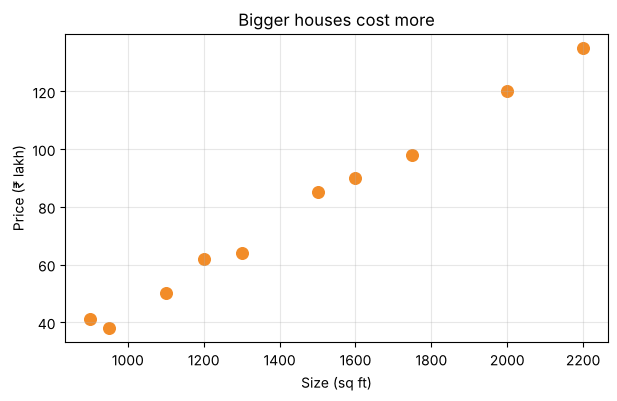

In [16]:
plt.scatter(houses["size_sqft"], houses["price_lakh"], color="#F28C28", s=70)
plt.xlabel("Size (sq ft)")
plt.ylabel("Price (₹ lakh)")
plt.title("Bigger houses cost more")
plt.grid(alpha=0.3)
plt.show()

---
## Part 4 · What is machine learning?

> **Machine learning = learning patterns from data to make predictions on new data.**

| Term | Meaning | In our house table |
|---|---|---|
| **Feature (X)** | an input the model looks at | size, rooms, age |
| **Label / target (y)** | the answer we want to predict | price |
| **Training set** | rows the model learns from | about 80% of rows |
| **Test set** | rows held back to check the model honestly | about 20% of rows |
| **Model** | the learned rule | `price = b0 + b1·size + …` |

Two big kinds of supervised problems:

* **Regression** predicts a **number** (price, marks) → *linear regression*
* **Classification** predicts a **category** (pass/fail, spam/not spam) → *logistic regression*

In [17]:
from sklearn.model_selection import train_test_split

X = houses[["size_sqft", "rooms", "age_years"]]   # features
y = houses["price_lakh"]                          # label

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 8 | Test rows: 2


---
## Part 5 · Linear regression: statistics way vs ML way

The equation is the **same** in both worlds:

$$\text{Price} = \beta_0 + \beta_1\,\text{Size} + \beta_2\,\text{Rooms} + \beta_3\,\text{Age} + \varepsilon$$

| | Statistics way | Machine-learning way |
|---|---|---|
| Goal | **explain** the effect of each variable | **predict** new cases accurately |
| Data | fit on all rows | **train/test split** |
| How β is found | one formula (least squares) | **minimise error step by step** (gradient descent) |
| Judged by | p-values, R² | **error on unseen test data** (RMSE) |

### 5.1 The statistics way: one formula on all the data
The least-squares solution is $\hat\beta = (X^\top X)^{-1}X^\top y$.

In [18]:
X_all = np.column_stack([np.ones(len(houses)), houses[["size_sqft", "rooms", "age_years"]]])
beta = np.linalg.lstsq(X_all, houses["price_lakh"], rcond=None)[0]

for name, b in zip(["intercept", "size_sqft", "rooms", "age_years"], beta):
    print(f"{name:>10}: {b:8.3f}")

 intercept:  -17.945
 size_sqft:    0.068
     rooms:    0.460
 age_years:   -0.364


### 5.2 What does the machine actually learn? Gradient descent from scratch
The machine learns the **β numbers** by repeating four steps:

1. start with a guess (all β = 0)
2. predict every house: $\hat y = X\beta$
3. measure the error: $\text{MSE} = \frac{1}{n}\sum (y-\hat y)^2$
4. nudge each β downhill: $\beta \leftarrow \beta - \alpha \cdot \frac{\partial\,\text{MSE}}{\partial \beta}$

Features are **standardised** first (mean 0, sd 1) so one step size α suits all of them.

Learned β (standardised scale): [82.5  22.3   4.48 -7.24]
MSE at start: 7806.2 → at end: 9.5


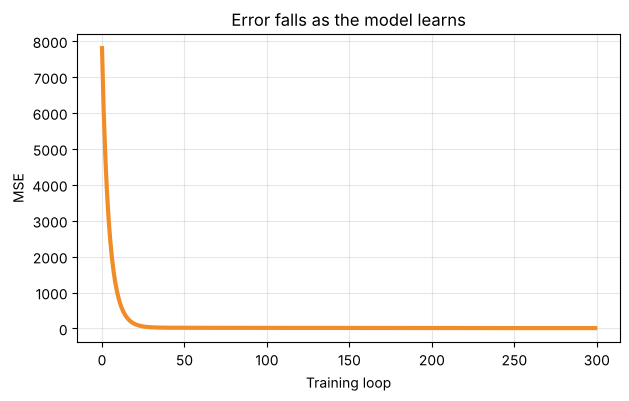

In [19]:
Xs = (X_train - X_train.mean()) / X_train.std()     # standardise
Xs = np.column_stack([np.ones(len(Xs)), Xs])        # add intercept column
yt = y_train.to_numpy()

beta = np.zeros(Xs.shape[1])     # step 1: guess
alpha = 0.05                     # learning rate
history = []

for step in range(300):
    y_hat = Xs @ beta                              # step 2: predict
    error = y_hat - yt
    history.append((error ** 2).mean())            # step 3: MSE
    gradient = 2 * Xs.T @ error / len(yt)
    beta = beta - alpha * gradient                 # step 4: update

print("Learned β (standardised scale):", beta.round(2))
print("MSE at start:", round(history[0], 1), "→ at end:", round(history[-1], 1))

plt.plot(history, color="#F28C28", lw=3)
plt.xlabel("Training loop"); plt.ylabel("MSE")
plt.title("Error falls as the model learns")
plt.grid(alpha=0.3); plt.show()

### 5.3 The ML way with scikit-learn
Every scikit-learn model follows the same three verbs: **`fit` → `predict` → `score`**.

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)
rmse = mean_squared_error(y_test, pred) ** 0.5

print("Coefficients:", dict(zip(X.columns, lin.coef_.round(3).tolist())))
print("Test RMSE   :", round(rmse, 2), "lakh")

new_house = pd.DataFrame({"size_sqft": [1650], "rooms": [3], "age_years": [8]})
print("Predicted price of the new house: ₹", lin.predict(new_house).round(1)[0], "lakh")

Coefficients: {'size_sqft': 0.074, 'rooms': -0.57, 'age_years': -0.067}
Test RMSE   : 3.11 lakh
Predicted price of the new house: ₹ 93.1 lakh


> **Key idea:** the equation did not change. What made it *machine learning* is the workflow around it:
> hold out test data, minimise a loss, check error on unseen rows, then **save the fitted β's** and reuse them to predict new houses.

---
## Part 6 · Logistic regression

### 6.1 Why not just use linear regression for pass/fail?
Suppose the target is **passed = 1** or **failed = 0**. A straight line can predict values like −0.3 or 1.4, which make no sense as probabilities.

Logistic regression squeezes the straight line through the **sigmoid** function so the output is always between 0 and 1:

$$z = \beta_0 + \beta_1 x \qquad\qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

* $p$ is the **probability** of class 1 (pass)
* predict **pass** if $p \ge 0.5$, otherwise **fail** (0.5 is the default *threshold*)

sigmoid(-4) = 0.018
sigmoid( 0) = 0.500
sigmoid( 2) = 0.881
sigmoid( 4) = 0.982


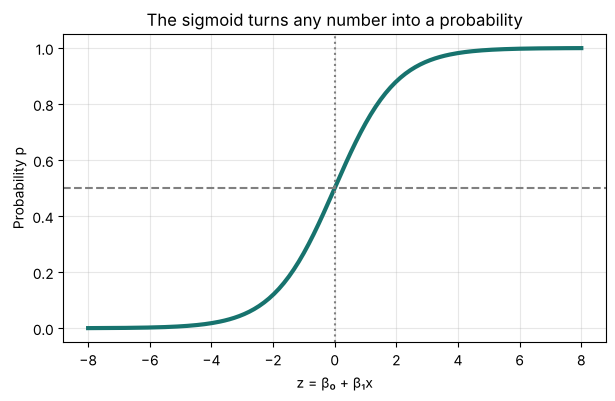

In [21]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z), color="#17736E", lw=3)
plt.axhline(0.5, ls="--", color="grey")
plt.axvline(0, ls=":", color="grey")
plt.xlabel("z = β₀ + β₁x"); plt.ylabel("Probability p")
plt.title("The sigmoid turns any number into a probability")
plt.grid(alpha=0.3); plt.show()

for v in [-4, 0, 2, 4]:
    print(f"sigmoid({v:>2}) = {sigmoid(v):.3f}")

### 6.2 Odds and log-odds: the link to statistics
Rearranging the sigmoid gives

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x$$

* $\frac{p}{1-p}$ is the **odds** (e.g. p = 0.8 → odds 4 : 1)
* the **log-odds** are a straight line in $x$, which is why it is still called *regression*
* $e^{\beta_1}$ is the **odds ratio**: how many times the odds multiply for one extra unit of $x$

### 6.3 Data: hours studied vs passing the exam
We simulate 200 students. More study hours means a higher chance of passing.

In [22]:
n = 200
hours = np.round(np.random.uniform(0, 10, n), 1)
attendance = np.round(np.clip(np.random.normal(75, 12, n), 30, 100))
true_z = -6 + 0.9 * hours + 0.03 * attendance
passed = (np.random.rand(n) < sigmoid(true_z)).astype(int)

exam = pd.DataFrame({"hours": hours, "attendance": attendance, "passed": passed})
print(exam.head())
print("\nPass rate:", exam["passed"].mean().round(2))

   hours  attendance  passed
0    3.7        67.0       0
1    9.5        78.0       1
2    7.3        79.0       1
3    6.0        66.0       1
4    1.6        97.0       1

Pass rate: 0.54


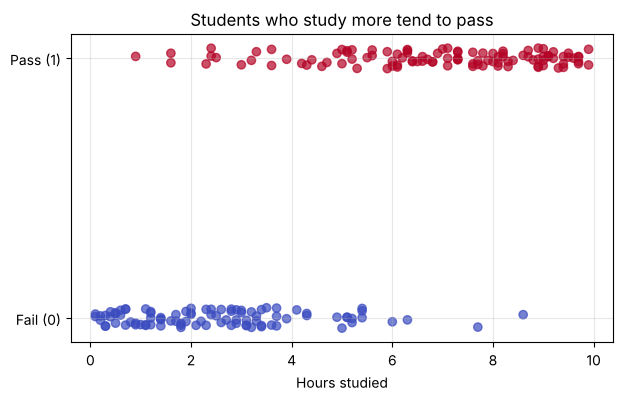

In [23]:
plt.scatter(exam["hours"], exam["passed"] + np.random.uniform(-0.04, 0.04, n),
            c=exam["passed"], cmap="coolwarm", alpha=0.7)
plt.yticks([0, 1], ["Fail (0)", "Pass (1)"])
plt.xlabel("Hours studied")
plt.title("Students who study more tend to pass")
plt.grid(alpha=0.3); plt.show()

### 6.4 Fit a one-feature model: hours → pass

In [24]:
from sklearn.linear_model import LogisticRegression

X1 = exam[["hours"]]          # double brackets keep it 2-D (a table)
y1 = exam["passed"]
X_tr, X_te, y_tr, y_te = train_test_split(X1, y1, test_size=0.25,
                                          random_state=42, stratify=y1)

logit1 = LogisticRegression().fit(X_tr, y_tr)
b0, b1 = logit1.intercept_[0], logit1.coef_[0, 0]

print(f"log-odds = {b0:.2f} + {b1:.2f} × hours")
print(f"Odds ratio per extra hour = e^{b1:.2f} = {np.exp(b1):.2f}")
print(f"50/50 point (decision boundary) = {-b0 / b1:.1f} hours")

log-odds = -3.85 + 0.87 × hours
Odds ratio per extra hour = e^0.87 = 2.39
50/50 point (decision boundary) = 4.4 hours


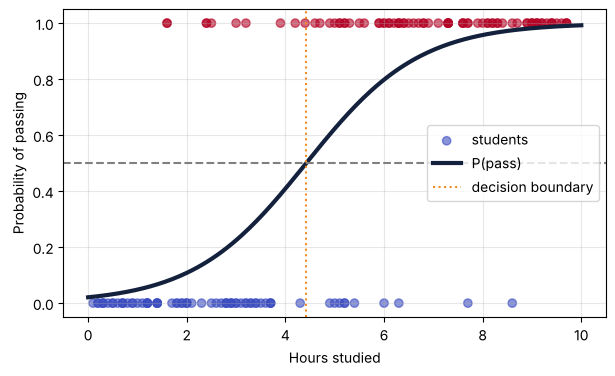

In [25]:
grid = pd.DataFrame({"hours": np.linspace(0, 10, 200)})
plt.scatter(X_tr["hours"], y_tr, c=y_tr, cmap="coolwarm", alpha=0.6, label="students")
plt.plot(grid["hours"], logit1.predict_proba(grid)[:, 1], color="#14213D", lw=3,
         label="P(pass)")
plt.axhline(0.5, ls="--", color="grey")
plt.axvline(-b0 / b1, ls=":", color="#F28C28", label="decision boundary")
plt.xlabel("Hours studied"); plt.ylabel("Probability of passing")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 6.5 Predict probabilities and classes for new students

In [26]:
new_students = pd.DataFrame({"hours": [1.5, 4.0, 6.5, 9.0]})
new_students["P(pass)"]   = logit1.predict_proba(new_students[["hours"]])[:, 1].round(2)
new_students["predicted"] = logit1.predict(new_students[["hours"]])
new_students

,hours,P(pass),predicted
0,1.5,0.07,0
1,4.0,0.41,0
2,6.5,0.86,1
3,9.0,0.98,1


### 6.6 Two features: hours and attendance

In [27]:
X2 = exam[["hours", "attendance"]]
y2 = exam["passed"]
X_tr, X_te, y_tr, y_te = train_test_split(X2, y2, test_size=0.25,
                                          random_state=42, stratify=y2)

logit2 = LogisticRegression().fit(X_tr, y_tr)
print("Coefficients:", dict(zip(X2.columns, logit2.coef_[0].round(3).tolist())))
print("Odds ratios :", dict(zip(X2.columns, np.exp(logit2.coef_[0]).round(3).tolist())))
print("Test accuracy:", round(logit2.score(X_te, y_te), 3))

Coefficients: {'hours': 0.879, 'attendance': 0.03}
Odds ratios : {'hours': 2.409, 'attendance': 1.03}
Test accuracy: 0.82


---
## Part 7 · Evaluating a classifier

Accuracy alone can mislead (if 95% of students pass, a model that always says "pass" is 95% accurate but useless).

| | Predicted fail (0) | Predicted pass (1) |
|---|---|---|
| **Actually fail (0)** | True negative (TN) | False positive (FP) |
| **Actually pass (1)** | False negative (FN) | True positive (TP) |

* **Precision** = TP / (TP + FP): of those we said "pass", how many really passed?
* **Recall** = TP / (TP + FN): of those who really passed, how many did we catch?
* **F1** = balance of precision and recall
* **ROC AUC**: how well the probabilities rank passers above failers (0.5 = guessing, 1 = perfect)

              precision    recall  f1-score   support

        Fail       0.77      0.87      0.82        23
        Pass       0.88      0.78      0.82        27

    accuracy                           0.82        50
   macro avg       0.82      0.82      0.82        50
weighted avg       0.83      0.82      0.82        50



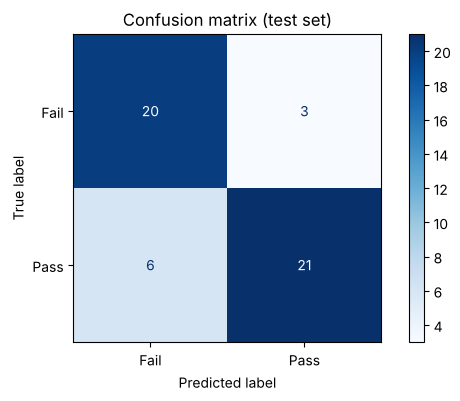

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

pred = logit2.predict(X_te)
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

print(classification_report(y_te, pred, target_names=["Fail", "Pass"]))

ROC AUC: 0.91


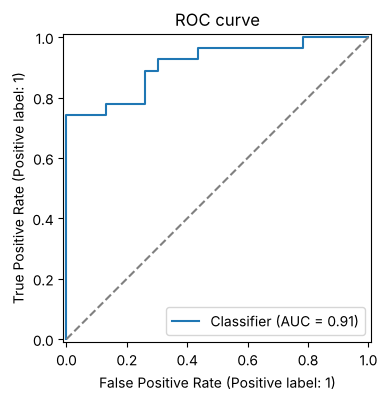

In [29]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

proba = logit2.predict_proba(X_te)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_te, proba), 3))
RocCurveDisplay.from_predictions(y_te, proba)
plt.plot([0, 1], [0, 1], ls="--", color="grey")
plt.title("ROC curve"); plt.show()

### 7.1 Changing the threshold
0.5 is not sacred. Lowering it catches more passers (**higher recall**) but raises false alarms (**lower precision**).

In [30]:
from sklearn.metrics import precision_score, recall_score

rows = []
for t in [0.3, 0.5, 0.7]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": round(precision_score(y_te, p), 2),
                 "recall":    round(recall_score(y_te, p), 2)})
pd.DataFrame(rows)

,threshold,precision,recall
0,0.3,0.80,0.89
1,0.5,0.88,0.78
2,0.7,1.00,0.74


---
## Part 8 · A real dataset: breast cancer diagnosis

scikit-learn ships with a real medical dataset: 569 tumour samples, 30 measurements each, labelled **malignant (0)** or **benign (1)**.

We use a **pipeline** that (1) standardises features and (2) fits logistic regression, and **5-fold cross-validation** for a more reliable score.

In [31]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

cancer = load_breast_cancer(as_frame=True)
df = cancer.frame
print("Shape:", df.shape)
print(df["target"].value_counts().rename({0: "malignant", 1: "benign"}))
df.iloc[:5, :6]          # slicing: first 5 rows, first 6 columns

Shape: (569, 31)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


In [32]:
X = df.drop(columns="target")
y = df["target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

cv = cross_val_score(model, X_tr, y_tr, cv=5, scoring="accuracy")
print("5-fold CV accuracy:", cv.round(3), "| mean =", cv.mean().round(3))

model.fit(X_tr, y_tr)
print("Test accuracy     :", round(model.score(X_te, y_te), 3))
print("Test ROC AUC      :", round(roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]), 3))

5-fold CV accuracy: [0.967 0.978 0.967 1.    0.989] | mean = 0.98
Test accuracy     : 0.982
Test ROC AUC      : 0.995


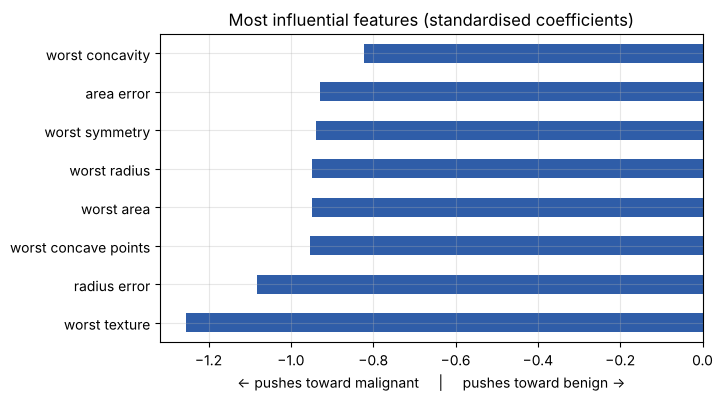

In [33]:
coefs = pd.Series(model[-1].coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:8]

top.sort_values().plot.barh(color=["#2F5DA8" if v < 0 else "#F28C28" for v in top.sort_values()])
plt.title("Most influential features (standardised coefficients)")
plt.xlabel("← pushes toward malignant     |     pushes toward benign →")
plt.grid(alpha=0.3); plt.show()

### 8.1 Save the model and reuse it
A trained model is just stored numbers. Save it once, load it later, and predict without retraining.

In [34]:
import joblib

joblib.dump(model, "breast_cancer_logit.joblib")
loaded = joblib.load("breast_cancer_logit.joblib")
print("Prediction for first 5 test rows:", loaded.predict(X_te.iloc[:5]))
print("Actual labels                   :", y_te.iloc[:5].to_numpy())

Prediction for first 5 test rows: [0 1 0 1 0]
Actual labels                   : [0 1 0 1 0]


---
## Part 9 · Practice exercises

Try these on your own. Add a new cell below each one.

1. **Slicing:** from `marks`, get the 2nd to 5th items, then every item at an odd index.
2. **NumPy:** from `data`, select the rows where hours studied ≥ 5 and show only the attendance column.
3. **pandas:** using `houses`, find the average price of houses with 3 rooms. Use both `loc` and a boolean filter.
4. **Linear regression:** add `price_per_sqft` as a feature. Does test RMSE improve? Why might this be cheating? *(Hint: it is computed from the price.)*
5. **Logistic regression:** in the exam data, what is the predicted probability of passing for a student with 5 hours and 90% attendance?
6. **Threshold:** for the cancer model, missing a malignant tumour is costly. Should you raise or lower the threshold for predicting *benign*? Test your answer.

---
## Summary

| Concept | One-line takeaway |
|---|---|
| Slicing | `seq[start:stop:step]`, stop is excluded; `arr[rows, cols]` for 2-D |
| `iloc` vs `loc` | position (stop excluded) vs label/condition (stop included) |
| ML | learn patterns from data, judge on **unseen** data |
| Linear regression | predicts a number; ML adds split, loss minimisation, test error |
| Logistic regression | predicts a probability with the sigmoid; coefficients are log-odds |
| Evaluation | look beyond accuracy: precision, recall, ROC AUC, threshold |